# Aprendizaje de Simbolo: `ParabolicMLPSymbol` con datos GRF (calor 1D)

Se aprende un simbolo escalar real $a_\theta:\mathbb{Z}^n\to\mathbb{R}$ con la reparametrizacion parabolica
$a_\theta(\mathbf{k})=\langle\mathbf{k}\rangle^m\big(c+(C-c)\,\sigma(g_\theta(\mathbf{k}/\langle\mathbf{k}\rangle))\big)$ para
$\mathbf{k}\neq0$ y $a_\theta(0)=0$, con $g_\theta$ una MLP con `Tanh`. Es la misma corrida que
`02_barrido.ipynb`, cambiando solo los datos: ahora son los de la ecuacion del calor 1D del
paper base (Sec. 5.1), con condiciones iniciales de un campo aleatorio gaussiano.

**Función de perdida**

$$\mathcal{L} = \lambda_{\text{traj}}\,\mathcal{L}_{\text{traj}} + \lambda_{\text{par}}\,\mathcal{L}_{\text{par}} + \lambda_{\text{class}}\,\mathcal{L}_{\text{class}}$$

- **Trayectoria:** $\mathcal{L}_{\text{traj}} = \mathbb{E}\big[|e^{-t a_\theta(\mathbf{k})}\hat u_0(\mathbf{k}) - \hat u_{\text{ref}}(\mathbf{k},t)|^2\big]$
- **Parabolicidad (Def. 2.3):** $\mathcal{L}_{\text{par}} = \mathbb{E}\big[\max\big(0,\ |(a_\theta(\mathbf{k})+\lambda)^{-1}| - \kappa(1+|(\mathbf{k},\lambda)|^2)^{-m/2}\big)^2\big]$,
  sobre $\mathrm{Re}(\lambda)\ge 0$, $|(\mathbf{k},\lambda)|\ge\omega$.
- **Clase de simbolo $S^{m,\rho}$:**
  $\mathcal{L}_{\text{class}} = \mathbb{E}_{\mathbf{k}}\Big[\frac{1}{|A_\rho|}\sum_{\alpha\in A_\rho}\max\big(0,\ \langle\mathbf{k}\rangle^{|\alpha|-m}\,|\Delta^\alpha_k a_\theta(\mathbf{k})| - C_\alpha\big)^2\Big]$,
  con $A_\rho=\{\alpha\in\mathbb{N}_0^n : |\alpha|\le\rho\}$, $\langle\mathbf{k}\rangle=(1+|\mathbf{k}|^2)^{1/2}$ y
  $\Delta_{k_j}a(\mathbf{k})=a(\mathbf{k}+e_j)-a(\mathbf{k})$. 
Como referencia se usa el simbolo del calor $a(k) = |k|^2$ en $\mathbb{T}^1$
($n=1$, $m=2$, $\rho=n+1=2$ para el simbolo aprendido).

# Setup
- **Datos (`data/grf.py`):** $100$ condiciones iniciales GRF $\times$ $10$ tiempos, resolucion $1024$,
  quedandose solo con los pares $(k,t)$ recuperables en `float64`. La particion entrenamiento /
  validacion es **por $\mathbf{k}$** (80% / 20% de los $k$ unicos), igual que antes. Aparte hay un
  conjunto de **prueba**: $20$ condiciones iniciales nuevas y una rejilla temporal mas fina ($20$ tiempos).
- **$\kappa$:** $\kappa=$ `theoretical_kappa()`, con $c$ y $C$ estimados de los datos de entrenamiento
  (`estimate_symbol` + `estimate_bounds`, $\delta=0.1$).
- **Arquitecturas probadas:** barrido de $\{2,3,4\}$ capas ocultas $\times$ $\{32,64,128\}$ neuronas.
- **Regularizacion:** dropout $0.2$ en las capas ocultas interiores (se compara `none` frente a
  `middle`), weight decay $\{0,\ 10^{-4}\}$ en las `Linear` ocultas interiores, y **early stopping**
  sobre la perdida total de validacion, **incluyendo $\mathcal{L}_{\text{class}}$** (evaluada cada epoca
  sobre un conjunto fijo de $\mathbf{k}$ con $|k_i|\le k_{\max}$).

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from parabolic_symbol.verification.parabolicity import ParabolicityVerifier
from parabolic_symbol.verification.symbol_class import SymbolClassVerifier
from parabolic_symbol.symbols.heat import HeatSymbol
from parabolic_symbol.utils import default_device
from parabolic_symbol.symbols.parabolic_mlp_symbol import ParabolicMLPSymbol
from parabolic_symbol.data.synthetic import k_grid, phase_grid, split_trajectory_data
from parabolic_symbol.data.grf import field_rel_l2, heat_grf_datasets
from parabolic_symbol.learning.estimation import estimate_bounds, estimate_symbol
from parabolic_symbol.learning.evaluation import max_ratio_on, symbol_report, trajectory_report
from parabolic_symbol.learning.sweep import best_run, run_sweep, sweep_table
from parabolic_symbol.learning.training import TrainingConfig

np.set_printoptions(precision=4, suppress=True)

device = default_device()
dtype = torch.float64
print(f"device = {device}  |  dtype = {dtype}")

RESULTS = Path("../results/03_barrido_grf")   # tabla del barrido (CSV) y figuras (PNG)
RESULTS.mkdir(parents=True, exist_ok=True)

device = cuda  |  dtype = torch.float64


## 1. Datos de referencia

Ecuacion del calor en $\mathbb{T}^1=[0,2\pi)$ con la convencion del repo,
$u(x)=\sum_k \hat u(k)e^{ikx}$ y $a(k)=|k|^2$ (`HeatSymbol`):

- $u_0\sim\mathcal N\big(0,\ 7^4(-\Delta+7^2)^{-2.5}\big)$, real, muestreado espectralmente en una malla de
  $1024$ puntos, con varianza de cada modo proporcional a $7^4(|k|^2+49)^{-2.5}$.
- Solucion exacta: $\hat u(t,k)=e^{-t\,a(k)}\hat u_0(k)$.
- Entrenamiento: $100$ condiciones iniciales, $t=0.05+0.1j$, $j=0,\dots,9$.
  Prueba: $20$ condiciones iniciales nuevas, $t=0.05+0.05j$, $j=0,\dots,19$.
- **Mascara de recuperabilidad:** se descartan los pares $(k,t)$ con $e^{-t\,a(k)}\le\varepsilon_{\texttt{float64}}$,
  donde $\hat u(t,k)$ cae por debajo de la precision de maquina. La ventana de $k$ que queda fija
  $k_{\max}$ del resto del notebook.


In [3]:
n = 1
reference = HeatSymbol(n=n)

grf_train, grf_test = heat_grf_datasets(reference, resolution=1024, dtype=dtype, seed=0)
test_data = grf_test.split
k_max = grf_train.window.k_inf_max   # ventana de k recuperable

# Particion por k: cada k unico va entero a entrenamiento o a validacion.
train_data, val_data = split_trajectory_data(grf_train.split, val_fraction=0.2, seed=0)

k_train_values = np.unique(train_data["k"].numpy(), axis=0)
k_val_values = np.unique(val_data["k"].numpy(), axis=0)

print()
print(f"k_max = {k_max}  (ventana recuperable)")
print(f"entrenamiento: {train_data['k'].shape[0]:,} muestras / {len(k_train_values)} k unicos")
print(f"validacion:    {val_data['k'].shape[0]:,} muestras / {len(k_val_values)} k unicos")
print(f"prueba:        {test_data['k'].shape[0]:,} muestras / {grf_test.window.n_k} k unicos")


ENTRENAMIENTO
100 condiciones iniciales x 10 tiempos, resolucion 1024: 218 de 10240 pares (k, t) recuperables (eps=2.22e-16) -> 21,800 muestras
  ventana de k recuperable: 53 k, |k|_inf <= 26, |k| in [0, 26]
  max |k| por tiempo: t=0.05:26, t=0.15:15, t=0.25:12, t=0.35:10, t=0.45:8, t=0.55:8, t=0.65:7, t=0.75:6, t=0.85:6, t=0.95:6
PRUEBA
20 condiciones iniciales x 20 tiempos, resolucion 1024: 408 de 20480 pares (k, t) recuperables (eps=2.22e-16) -> 8,160 muestras
  ventana de k recuperable: 53 k, |k|_inf <= 26, |k| in [0, 26]
  max |k| por tiempo: t=0.05:26, t=0.10:18, t=0.15:15, t=0.20:13, t=0.25:12, t=0.30:10, t=0.35:10, t=0.40:9, t=0.45:8, t=0.50:8, t=0.55:8, t=0.60:7, t=0.65:7, t=0.70:7, t=0.75:6, t=0.80:6, t=0.85:6, t=0.90:6, t=0.95:6, t=1.00:6

k_max = 26  (ventana recuperable)
entrenamiento: 15,900 muestras / 42 k unicos
validacion:    5,900 muestras / 11 k unicos
prueba:        8,160 muestras / 53 k unicos


## 2. $\kappa$ teorico y constantes $C_\alpha$

$c$ y $C$ se estiman solo con los datos de entrenamiento y fijan $\kappa=$ `theoretical_kappa()`.
$\hat\kappa$ del simbolo de referencia se calcula solo como comparacion.
Las constantes $C_\alpha$ de $\mathcal{L}_{\text{class}}$ se estiman igual, del simbolo analitico en la
ventana de entrenamiento y con un margen: asi la cota que se le exige a la red la satisface la respuesta
correcta, y el termino no la aleja de $|\mathbf{k}|^2$.

In [4]:
omega = 1.0
k_values = list(k_grid(n, k_max))
lam_values = [complex(re, im) for re in (0, 1, 5, 10, 25, 50) for im in (-50, -10, -2, 0, 2, 10, 50)]

kappa_ref = ParabolicityVerifier(reference).estimate_kappa(k_values, lam_values, omega=omega)

# Banda (c, C) desde los datos de ENTRENAMIENTO y kappa teorico de ParabolicMLPSymbol
k_est, a_hat = estimate_symbol(train_data, tol=1e-10)
bounds = estimate_bounds(k_est, a_hat, m=2.0, delta=0.1)
kappa_theo = ParabolicMLPSymbol(
    n=n, m=2.0, c=bounds.c, C=bounds.C, seed=0, device=device, dtype=dtype
).theoretical_kappa(omega)

# Constantes C_alpha de la Def. 2.1 para L_class, del simbolo analitico en |k_i| <= k_max
class_margin = 1.5
verifier_clase = SymbolClassVerifier(reference)
C_ref = {alpha: verifier_clase.estimate_constant(alpha, k_max)
         for alpha in verifier_clase.multi_indices()}
C_piso = min(c for c in C_ref.values() if c > 0)
class_C = {alpha: class_margin * max(c, C_piso) for alpha, c in C_ref.items()}

print(f"kappa_hat referencia = {kappa_ref:.4f}")
print(f"(c, C) de los datos  = ({bounds.c:.4f}, {bounds.C:.4f})   ventana: {bounds.window}")
print(f"kappa teorico        = {kappa_theo:.4f}")
print(f"C_alpha referencia   = { {str(a): round(c, 3) for a, c in C_ref.items()} }")
print(f"class_C (x{class_margin}, piso {C_piso:.3f}) = { {str(a): round(c, 3) for a, c in class_C.items()} }")

estimate_symbol: 12,800 de 15,900 pares (k, t) recuperables (tol=1e-10); 34 de 42 k de entrenamiento
  ventana usada: 34 k, |k|_inf <= 21, |k| in [0, 21]
kappa_hat referencia = 2.0000
(c, C) de los datos  = (0.4500, 1.0975)   ventana: 33 k, |k|_inf <= 21, |k| in [1, 21]
kappa teorico        = 3.1427
C_alpha referencia   = {'(0,)': 0.999, '(1,)': 2.236, '(2,)': 2.0, '(3,)': 0.0}
class_C (x1.5, piso 0.999) = {'(0,)': 1.498, '(1,)': 3.354, '(2,)': 3.0, '(3,)': 1.498}


## 3. Barrido de hiperparametros

Ejes: $3$ profundidades $\times$ $3$ anchos $\times$ ubicacion del dropout $\times$ $2$ weight decays $=$
**30 entrenamientos**, todos con $\kappa=$ `theoretical_kappa()`.

- **Dropout:** tasa **fija** de $0.2$; lo que se compara es *donde* se aplica, `none` frente a `middle`
  (capas ocultas interiores, excluyendo la primera y la ultima). Con $2$ capas ocultas `middle` no deja
  ninguna capa, asi que equivale a `none` y esa corrida no se repite.
- **Weight decay:** $\{0,\ 10^{-4}\}$, solo sobre las `Linear` ocultas interiores.


In [5]:
# Configuracion base: valores por defecto de TrainingConfig (learning/training.py); solo
# k_max y las C_alpha dependen de los datos.
base_config = TrainingConfig(k_max=k_max, class_C=class_C)

runs = run_sweep(
    train_data,
    val_data,
    n=n,
    m=2.0,
    bounds=(bounds.c, bounds.C),
    depths=[2, 3, 4],
    widths=[32, 64, 128],
    base_config=base_config,
    dropout=0.2,
    dropout_layers=["none", "middle"],
    weight_decays=[0.0, 1e-4],
    device=device,
    dtype=dtype,
)


[  1/30] 2x32  drop[-] wd=0e+00 | rel_l2=0.1425 |   5.1s
[  2/30] 2x32  drop[-] wd=1e-04 | rel_l2=0.1425 |   2.9s
[  3/30] 2x64  drop[-] wd=0e+00 | rel_l2=0.0048 |  15.8s
[  4/30] 2x64  drop[-] wd=1e-04 | rel_l2=0.0048 |  16.2s
[  5/30] 2x128 drop[-] wd=0e+00 | rel_l2=0.0109 |  15.7s
[  6/30] 2x128 drop[-] wd=1e-04 | rel_l2=0.0109 |  15.5s
[  7/30] 3x32  drop[-] wd=0e+00 | rel_l2=0.0047 |  14.1s
[  8/30] 3x32  drop[-] wd=1e-04 | rel_l2=0.0047 |  14.0s
[  9/30] 3x32  drop[1] wd=0e+00 | rel_l2=0.1130 |   3.3s
[ 10/30] 3x32  drop[1] wd=1e-04 | rel_l2=0.1130 |   4.0s
[ 11/30] 3x64  drop[-] wd=0e+00 | rel_l2=0.0057 |  21.8s
[ 12/30] 3x64  drop[-] wd=1e-04 | rel_l2=0.0057 |  22.0s
[ 13/30] 3x64  drop[1] wd=0e+00 | rel_l2=0.1042 |   4.6s
[ 14/30] 3x64  drop[1] wd=1e-04 | rel_l2=0.1042 |   4.7s
[ 15/30] 3x128 drop[-] wd=0e+00 | rel_l2=0.0094 |  14.7s
[ 16/30] 3x128 drop[-] wd=1e-04 | rel_l2=0.0094 |  14.7s
[ 17/30] 3x128 drop[1] wd=0e+00 | rel_l2=0.1041 |  12.3s
[ 18/30] 3x128 drop[1] wd=1e-04

## 4. Resultados del barrido

In [6]:
table = sweep_table(runs)
table.to_csv(RESULTS / "barrido.csv", index=False)
print(f"{len(table)} corridas, {table['segundos'].sum() / 60:.1f} min de entrenamiento en total")

# Todas las corridas, de mejor a peor error relativo de validacion:
COLS = ["capas", "ancho", "dropout", "weight_decay",
        "val_rel_l2", "val_total", "val_par_max_ratio"]
display(table[COLS].sort_values("val_rel_l2").reset_index(drop=True))


30 corridas, 6.8 min de entrenamiento en total


,capas,ancho,dropout,weight_decay,val_rel_l2,val_total,val_par_max_ratio
0,3,32,OFF,0.0000,0.004695,1.127021e-08,0.712255
1,3,32,OFF,0.0001,0.004695,1.127035e-08,0.712255
2,2,64,OFF,0.0000,0.004819,1.187545e-08,0.711665
3,2,64,OFF,0.0001,0.004819,1.187666e-08,0.711665
4,4,128,OFF,0.0000,0.005094,1.326830e-08,0.711595
5,4,128,OFF,0.0001,0.005094,1.326963e-08,0.711595
6,3,64,OFF,0.0001,0.005671,1.644340e-08,0.711470
7,3,64,OFF,0.0000,0.005671,1.644491e-08,0.711470
8,3,128,OFF,0.0000,0.009417,4.534343e-08,0.709121
9,3,128,OFF,0.0001,0.009417,4.534370e-08,0.709121


In [7]:
# Por configuracion de regularizacion (dropout / weight decay).
for eje in ("dropout", "weight_decay"):
    if table[eje].nunique() > 1:
        display(
            table.groupby(eje).agg(
                corridas=("val_rel_l2", "size"),
                mejor_val_rel_l2=("val_rel_l2", "min"),
                mejor_val_total=("val_total", "min"),
                peor_ratio=("val_par_max_ratio", "min"),
            )
        )


,corridas,mejor_val_rel_l2,mejor_val_total,peor_ratio
dropout,,,,
OFF,18,0.004695,1.127021e-08,0.616307
"ON p=0.2 capas[1,2]",6,0.103721,5.535636e-06,0.616307
ON p=0.2 capas[1],6,0.104104,5.566096e-06,0.616307


,corridas,mejor_val_rel_l2,mejor_val_total,peor_ratio
weight_decay,,,,
0.0000,15,0.004695,1.127021e-08,0.616307
0.0001,15,0.004695,1.127035e-08,0.616307


### Seleccion: la mejor aproximacion

Todas las corridas usan el mismo $\kappa=$ `theoretical_kappa()`, con el que la Def. 2.3 se satisface por
construccion, asi que se elige la de **menor error relativo de validacion** de la trayectoria.


In [8]:
best = best_run(runs)

symbol = best.symbol
print(f"kappa = theoretical_kappa() = {best.kappa:.4f}")

# Kappa que realmente exhibe el simbolo aprendido, medido sobre la REJILLA DE
# CERTIFICACION (seccion 7). Junto a kappa_ref (celda 6) dice
# cuanto se alejo el simbolo aprendido del simbolo verdadero.
cert_radii = np.logspace(-2, 3, 25)                    # |lambda| en [1e-2, 1e3]
cert_angles = np.linspace(-np.pi / 2, np.pi / 2, 25)   # incluye la frontera Re(lambda) = 0
cert_lam = (cert_radii[:, None] * np.exp(1j * cert_angles)).ravel()
cert_k_max = 3 * k_max

kappa_learned = ParabolicityVerifier(symbol).estimate_kappa(
    list(k_grid(n, cert_k_max)), cert_lam, omega=omega
)
print(f"kappa_hat aprendido         = {kappa_learned:.4f}   (certificacion, |k_i| <= {cert_k_max})")
print(f"kappa_hat referencia        = {kappa_ref:.4f}   (simbolo analitico, celda 6)")

print(f"arquitectura elegida    = {best.n_layers} capas x {best.width} neuronas")
print(f"dropout                 = {best.dropout_desc}")
print(f"weight decay            = {best.weight_decay:g}  (Linear ocultas interiores)")
print(f"early stopping          = mejor epoca {best.best_epoch} de {best.epochs_run} corridas")
print()
print("metricas de validacion en la mejor epoca:")
print(f"  total             = {best.val_total:.4e}")
print(f"  trayectoria       = {best.val_trajectory:.4e}")
print(f"  parabolicidad     = {best.val_parabolicity:.4e}   (0 => ningun punto viola la cota)")
print(f"  rel_l2            = {best.val_rel_l2:.4f}")
print(f"  peor ratio        = {best.val_par_max_ratio:.4f}")
print(f"  puntos con >1     = {100 * best.val_par_violation:.2f}%")


kappa = theoretical_kappa() = 3.1427
kappa_hat aprendido         = 2.2380   (certificacion, |k_i| <= 78)
kappa_hat referencia        = 2.0000   (simbolo analitico, celda 6)
arquitectura elegida    = 3 capas x 32 neuronas
dropout                 = OFF
weight decay            = 0  (Linear ocultas interiores)
early stopping          = mejor epoca 106 de 136 corridas

metricas de validacion en la mejor epoca:
  total             = 1.1270e-08
  trayectoria       = 1.1270e-08
  parabolicidad     = 0.0000e+00   (0 => ningun punto viola la cota)
  rel_l2            = 0.0047
  peor ratio        = 0.7123
  puntos con >1     = 0.00%


### Metricas del modelo seleccionado

Se presentan dos reportes distintos:

- **Trayectoria** $\hat u(\mathbf{k},t) = e^{-t a_\theta(\mathbf{k})}\hat u_0(\mathbf{k})$, sobre las muestras
  de entrenamiento y de validacion.
- **Simbolo** $a_\theta(\mathbf{k})$ frente a $|\mathbf{k}|^2$, por separado sobre los $k$ de entrenamiento y
  los $k$ de validacion (estos ultimos la red nunca los vio).

Se reportan RMSE, MAE y $R^2$.

In [9]:
traj = {"entrenamiento": trajectory_report(symbol, train_data),
        "validacion": trajectory_report(symbol, val_data)}
n_muestras = {split: int(rep.pop("n")) for split, rep in traj.items()}

print("TRAYECTORIA  -- residuo complejo |u_pred - u_ref|")
print(f"  muestras: {n_muestras['entrenamiento']:,} entrenamiento / {n_muestras['validacion']:,} validacion")
display(pd.DataFrame(traj))

# El split es por k, asi que el simbolo se reporta por separado sobre los k de
# entrenamiento y sobre los k de validacion, que la red nunca vio.
sym = {"entrenamiento": symbol_report(symbol, reference, k_train_values),
       "validacion": symbol_report(symbol, reference, k_val_values)}
n_k = {split: int(rep.pop("n")) for split, rep in sym.items()}

print("SIMBOLO  -- a_theta(k) vs |k|^2")
print(f"  k unicos: {n_k['entrenamiento']} de entrenamiento / {n_k['validacion']} de validacion")
display(pd.DataFrame(sym))

print("PARABOLICIDAD")
print(f"  kappa usada             = {best.kappa:.4f}")
print(f"  hinge^2 de validacion   = {best.val_parabolicity:.4e}")


TRAYECTORIA  -- residuo complejo |u_pred - u_ref|
  muestras: 15,900 entrenamiento / 5,900 validacion


,entrenamiento,validacion
mse,6.418878e-09,1.127021e-08
rmse,8.011790e-05,1.061613e-04
mae,2.756008e-05,3.784278e-05
max_error,1.145004e-03,1.209265e-03
rel_l2,1.530599e-03,4.694777e-03
r2,9.999977e-01,9.999779e-01


SIMBOLO  -- a_theta(k) vs |k|^2
  k unicos: 42 de entrenamiento / 11 de validacion


,entrenamiento,validacion
mse,94.589857,98.345690
rmse,9.725732,9.916940
mae,7.385580,6.120783
max_error,19.962930,21.630097
rel_l2,0.031055,0.031333


PARABOLICIDAD
  kappa usada             = 3.1427
  hinge^2 de validacion   = 0.0000e+00


### Evaluacion en prueba

Condiciones iniciales nuevas y rejilla temporal fina ($20$ tiempos, incluidos tiempos que no estan en
entrenamiento). Se reportan dos errores relativos $L^2$:

- sobre los pares $(k,t)$ recuperables del conjunto de prueba (el mismo `trajectory_report`);
- en espacio fisico, como en el paper: $\|u_\theta(t,\cdot)-u(t,\cdot)\|_{L^2}/\|u(t,\cdot)\|_{L^2}$ en la malla
  de $1024$ puntos, con todos los modos, por condicion inicial y tiempo, promediado.


PRUEBA  -- 8,160 pares recuperables, 20 condiciones iniciales nuevas


,prueba
mse,5.292108e-09
rmse,7.274688e-05
mae,2.540930e-05
max_error,8.427410e-04
rel_l2,1.604022e-03
r2,9.999974e-01


error relativo L2 (pares recuperables) = 1.6040e-03
error relativo L2 (espacio fisico)     = 9.7959e-04  (medio; max 6.2649e-03)


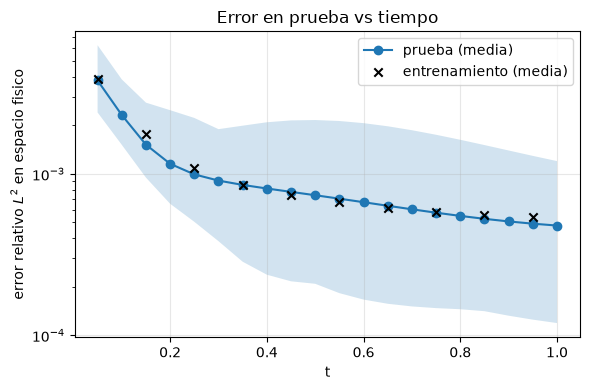

In [10]:
test_traj = trajectory_report(symbol, test_data)
test_traj.pop("n")
print(f"PRUEBA  -- {test_data['k'].shape[0]:,} pares recuperables, {grf_test.u0_hat.shape[0]} condiciones iniciales nuevas")
display(pd.DataFrame({"prueba": test_traj}))

err_field = field_rel_l2(symbol, grf_test)   # (n_ic, T)
print(f"error relativo L2 (pares recuperables) = {test_traj['rel_l2']:.4e}")
print(f"error relativo L2 (espacio fisico)     = {err_field.mean():.4e}  "
      f"(medio; max {err_field.max():.4e})")

fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(grf_test.t, err_field.mean(axis=0), "o-", label="prueba (media)")
ax.fill_between(grf_test.t, err_field.min(axis=0), err_field.max(axis=0), alpha=0.2)
ax.scatter(grf_train.t, field_rel_l2(symbol, grf_train).mean(axis=0), color="k", marker="x",
           zorder=3, label="entrenamiento (media)")
ax.set_xlabel("t")
ax.set_ylabel(r"error relativo $L^2$ en espacio fisico")
ax.set_title("Error en prueba vs tiempo")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(RESULTS / "error_prueba.png", dpi=150)
plt.show()


## 5. Curvas de entrenamiento

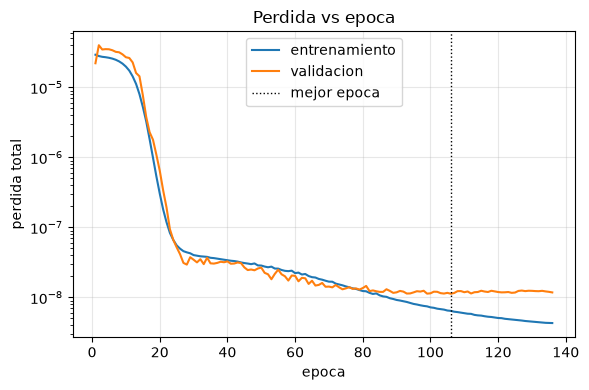

In [11]:
history = best.result.history
epochs = np.arange(1, len(history["train"]["total"]) + 1)

fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(epochs, history["train"]["total"], label="entrenamiento")
ax.semilogy(epochs, history["val"]["total"], label="validacion")
ax.axvline(best.best_epoch, color="k", ls=":", lw=1, label="mejor epoca")
ax.set_xlabel("epoca")
ax.set_ylabel("perdida total")
ax.set_title("Perdida vs epoca")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
fig.savefig(RESULTS / "perdida.png", dpi=150)
plt.show()


La perdida total graficada es la que registra `evaluate_split`: trayectoria + parabolicidad +
$\mathcal{L}_{\text{class}}$ (por `early_stopping_class=True`), y el early stopping usa esa misma cantidad.

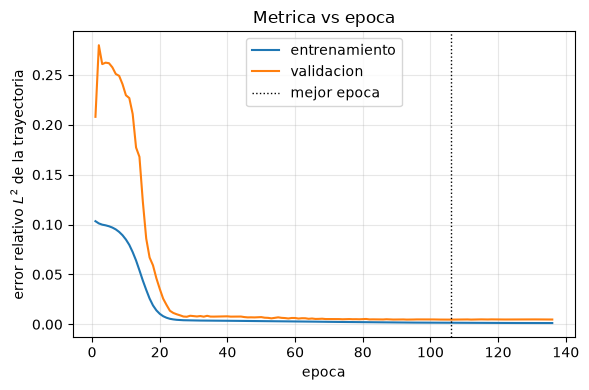

In [12]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(epochs, history["train"]["rel_l2"], label="entrenamiento")
ax.plot(epochs, history["val"]["rel_l2"], label="validacion")
ax.axvline(best.best_epoch, color="k", ls=":", lw=1, label="mejor epoca")
ax.set_xlabel("epoca")
ax.set_ylabel(r"error relativo $L^2$ de la trayectoria")
ax.set_title("Metrica vs epoca")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
fig.savefig(RESULTS / "rel_l2.png", dpi=150)
plt.show()


**Nota:** La linea punteada vertical marca la epoca cuyos pesos restauro el early stopping.

## 6. Simbolo aprendido vs. referencia

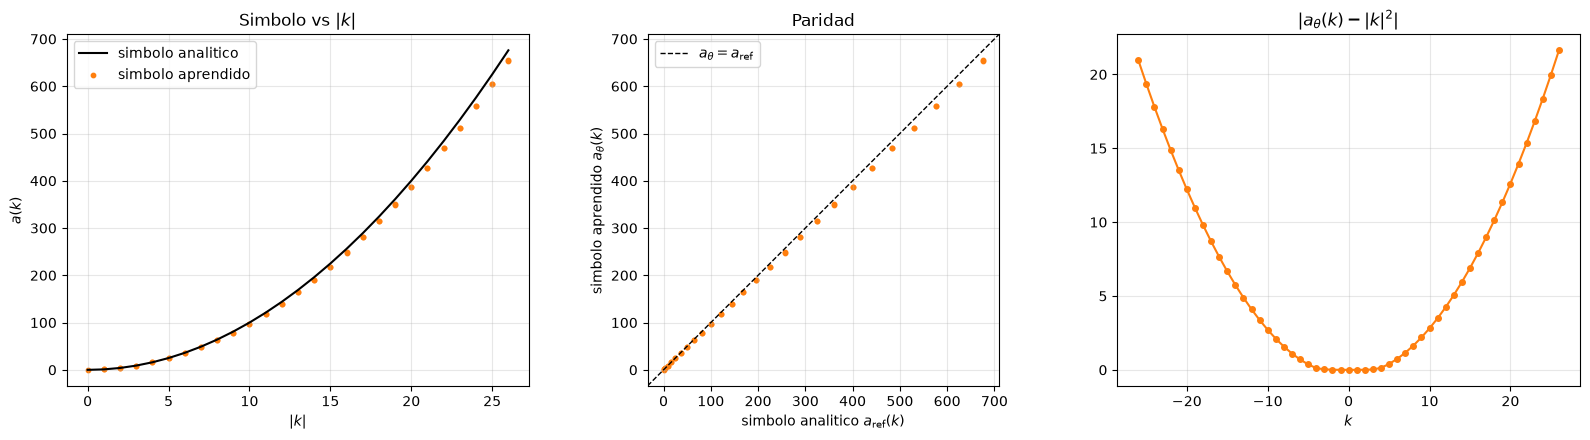

error relativo medio = 0.024, maximo = 0.032


In [13]:
k_arr = np.array(k_values)
a_true = np.array([reference(k)[0, 0] for k in k_values])
a_learn = symbol.evaluate_batch(k_arr)   # un solo forward por lotes
norm_k2 = np.sum(k_arr**2, axis=1)
norm_k = np.linalg.norm(k_arr, axis=1)

# Los dos simbolos son reales; np.real descarta la parte imaginaria nula que
# arrastra la interfaz compleja de Symbol.
a_ref_r, a_theta_r = np.real(a_true), np.real(a_learn)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# (a) La curva del simbolo. Para el calor, a(k) = |k|^2 es una parabola en |k|.
order = np.argsort(norm_k)
axes[0].plot(norm_k[order], a_ref_r[order], "k-", lw=1.5, label="simbolo analitico")
axes[0].scatter(norm_k, a_theta_r, s=10, color="C1", label="simbolo aprendido")
axes[0].set_xlabel(r"$|k|$")
axes[0].set_ylabel(r"$a(k)$")
axes[0].set_title(r"Simbolo vs $|k|$")
axes[0].legend()
axes[0].grid(alpha=0.3)

# (b) Paridad: cada k es un punto; sobre la diagonal significa que a_theta acerto.
lo = min(a_ref_r.min(), a_theta_r.min())
hi = max(a_ref_r.max(), a_theta_r.max())
pad = 0.05 * (hi - lo)
lims = [lo - pad, hi + pad]
axes[1].plot(lims, lims, "k--", lw=1, label=r"$a_\theta = a_{\text{ref}}$")
axes[1].scatter(a_ref_r, a_theta_r, s=10, color="C1")
axes[1].set_xlim(lims)
axes[1].set_ylim(lims)
axes[1].set_aspect("equal")
axes[1].set_xlabel(r"simbolo analitico $a_{\mathrm{ref}}(k)$")
axes[1].set_ylabel(r"simbolo aprendido $a_\theta(k)$")
axes[1].set_title("Paridad")
axes[1].legend()
axes[1].grid(alpha=0.3)

# (c) Error absoluto sobre la rejilla de k (n = 1: una sola coordenada).
axes[2].plot(k_arr[:, 0], np.abs(a_learn - a_true), "o-", color="C1", ms=4)
axes[2].set_title(r"$|a_\theta(k) - |k|^2|$")
axes[2].set_xlabel(r"$k$")
axes[2].grid(alpha=0.3)
plt.tight_layout()
fig.savefig(RESULTS / "simbolo.png", dpi=150)
plt.show()

rel = np.abs(a_learn - a_true) / np.maximum(norm_k2, 1)
print(f"error relativo medio = {rel.mean():.3f}, maximo = {rel.max():.3f}")


Para $|\mathbf{k}|$ grande $e^{-t|\mathbf{k}|^2}\approx 0$ en casi todo el rango de $t$, asi que la perdida de
trayectoria da poca informacion alli y el error es mayor.

## 7. Certificacion de Parabolicidad

La certificacion usa una rejilla **independiente** de `lam_values` (con la que se estimo $\hat\kappa$
de la referencia) y de los puntos de entrenamiento, y solo se evalua sobre el modelo ya elegido. Se
define en la celda de seleccion, que ya la usa para medir $\hat\kappa$ del simbolo aprendido:

- $k$ en $|k_i|\le 3k_{\max}$, tres veces la ventana de entrenamiento;
- $|\lambda|$ log-espaciado en $[10^{-2},10^{3}]$ con $25$ angulos en $[-\pi/2,\pi/2]$,
  extremos incluidos (la frontera $\mathrm{Re}(\lambda)=0$).


In [14]:
# Rejilla de CERTIFICACION (cert_lam, cert_k_max): definida en la celda de seleccion.


def cert_max_ratio(k_window, chunk=200_000):
    """Peor ratio sobre (|k_i| <= k_window) x cert_lam, por trozos para no llenar memoria."""
    kk, ll = phase_grid(n, k_window, cert_lam, device=device, dtype=dtype)
    return max(
        max_ratio_on(symbol, (kk[i : i + chunk], ll[i : i + chunk]), omega, best.kappa)
        for i in range(0, kk.shape[0], chunk)
    )


n_k_cert = len(k_grid(n, cert_k_max))
max_ratio = cert_max_ratio(cert_k_max)

print(f"{symbol!r}")
print(f"rejilla de certificacion: {n_k_cert:,} k (|k_i| <= {cert_k_max}) x "
      f"{len(cert_lam)} lambda = {n_k_cert * len(cert_lam):,} puntos")
print(f"kappa usada = {best.kappa:.4f}")
print(f"max ratio   = {max_ratio:.4f}   (<= 1 => la cota se satisface)")
print(f"satisfecha  = {max_ratio <= 1.0}")
print(f"kappa minimo que certificaria esta rejilla = {best.kappa * max_ratio:.4f}")


ParabolicMLPSymbol(c=0.45, C=1.098, hidden=(32, 32, 32), sin dropout)(n=1, m=2.0, rho=2, dim=1)
rejilla de certificacion: 157 k (|k_i| <= 78) x 625 lambda = 98,125 puntos
kappa usada = 3.1427
max ratio   = 0.7121   (<= 1 => la cota se satisface)
satisfecha  = True
kappa minimo que certificaria esta rejilla = 2.2380


In [15]:
# Hasta donde alcanza: peor ratio por ventana de k, con la misma rejilla de lambda.
# La parabolicidad solo puede esperarse dentro de la ventana muestreada.
for window in (k_max, 2 * k_max, cert_k_max):
    ratio = cert_max_ratio(window)
    donde = "dentro" if window <= k_max else "fuera "
    print(f"|k_i| <= {window:3d} ({donde} de la ventana de entrenamiento): "
          f"max ratio = {ratio:.4f} -> {'se satisface' if ratio <= 1.0 else 'NO se satisface'}")


|k_i| <=  26 (dentro de la ventana de entrenamiento): max ratio = 0.7121 -> se satisface
|k_i| <=  52 (fuera  de la ventana de entrenamiento): max ratio = 0.7121 -> se satisface
|k_i| <=  78 (fuera  de la ventana de entrenamiento): max ratio = 0.7121 -> se satisface


## 8. Clase del simbolo: $S^{m,\rho}$

La Def. 2.1 pide que, para todo multiindice $\alpha$ con $|\alpha|\le\rho$, exista $C_\alpha\ge 0$ con

$$\|\Delta^\alpha_k a(\mathbf{k})\|_{L(E)} \le C_\alpha\,\langle \mathbf{k}\rangle^{\,m-|\alpha|},
\qquad \langle \mathbf{k}\rangle=(1+|\mathbf{k}|^2)^{1/2},$$

con $\Delta_{k_j}a(\mathbf{k}) = a(\mathbf{k}+e_j)-a(\mathbf{k})$ (diferencia hacia adelante).
Se usa $\rho = $ `symbol.rho`.

`SymbolClassVerifier` estima $\hat C_\alpha(K)$ sobre ventanas crecientes $\{|k_i|\le K\}$ y mide la
pendiente log-log por capas de radio. **Es evidencia en una ventana finita, no una prueba:** la
definicion cuantifica sobre todo $\mathbb{Z}^n$, y la red solo esta restringida donde se la entreno.

La misma desigualdad es la que penaliza $\mathcal{L}_{\text{class}}$ durante el entrenamiento, pero solo
en los $\mathbf{k}$ muestreados ($|k_i|\le k_{\max}$). Esta seccion mira ventanas mas grandes para ver si la
penalizacion se sostiene fuera de esa region.

In [16]:
class_k_maxs = (4, 8, 12, 2 * k_max)   # ventanas crecientes para ver si C_alpha se estabiliza
resultados_clase = SymbolClassVerifier(symbol).check(k_maxs=class_k_maxs)

clase = pd.DataFrame([
    {
        "alpha": str(r.alpha),
        "|alpha|": r.order,
        **{f"C_hat({K})": r.c_hat[K] for K in class_k_maxs},
        f"crecim.({class_k_maxs[-2]}->{class_k_maxs[-1]})": r.growth,
        "pendiente": r.slope,
        "m-|alpha|": r.slope_theoretical,
        "estable": r.stable,
        "consistente": r.consistent,
    }
    for r in resultados_clase
])
display(clase)

ok = int(clase["consistente"].sum())
print(f"consistentes: {ok} de {len(clase)} multiindices (rho = {symbol.rho}, m = {symbol.m})")
print(f"ventana explorada: |k_i| <= {class_k_maxs[-1]} (evidencia, no prueba sobre todo Z^n)")
print("pendiente = nan significa Delta^alpha a = 0 en la ventana, asi que C_alpha = 0 basta")

,alpha,|alpha|,C_hat(4),C_hat(8),C_hat(12),C_hat(52),crecim.(12->52),pendiente,m-|alpha|,estable,consistente
0,"(0,)",0,0.934320,0.960381,0.964812,0.968085,1.003392,2.000775,2.0,True,True
1,"(1,)",1,2.244695,2.244695,2.244695,2.244695,1.000000,0.987331,1.0,True,True
2,"(2,)",2,2.017244,2.017244,2.017244,2.017244,1.000000,0.000012,0.0,True,True


consistentes: 3 de 3 multiindices (rho = 2, m = 2.0)
ventana explorada: |k_i| <= 52 (evidencia, no prueba sobre todo Z^n)
pendiente = nan significa Delta^alpha a = 0 en la ventana, asi que C_alpha = 0 basta
